# Health Insurance Churn Prediction — Phase 1: Data Exploration
**Project:** XAI-enhanced churn prediction for D365 CRM  
**Dataset:** IBM Telco Customer Churn (mapped to health insurance / D365 fields)  
**Goal:** Understand the data, clean it, and find the key patterns before modelling

## Cell 1 — Import libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Make charts look clean
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

print('Libraries loaded successfully')

Libraries loaded successfully


## Cell 2 — Load the dataset

In [5]:
# Load the CSV — update the path if your file is in a different folder
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

print(f'Dataset shape: {df.shape[0]} rows, {df.shape[1]} columns')
print(f'\nColumn names:')
print(df.columns.tolist())

Dataset shape: 7043 rows, 21 columns

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


## Cell 3 — Map columns to D365 / health insurance field names

This is academically important — it shows you understand how the dataset maps to a real CRM schema.  
We rename Telco columns to health insurance equivalents so the project reads as domain-specific.

In [6]:
# Rename columns to health insurance / D365 equivalents
column_mapping = {
    'customerID'       : 'policy_id',
    'gender'           : 'gender',
    'SeniorCitizen'    : 'is_senior',
    'Partner'          : 'has_dependants',
    'Dependents'       : 'has_family_cover',
    'tenure'           : 'policy_tenure_months',
    'PhoneService'     : 'has_dental_cover',
    'MultipleLines'    : 'has_multi_policy',
    'InternetService'  : 'plan_type',
    'OnlineSecurity'   : 'has_critical_illness_cover',
    'OnlineBackup'     : 'has_hospital_cover',
    'DeviceProtection' : 'has_mental_health_cover',
    'TechSupport'      : 'has_care_support',
    'StreamingTV'      : 'has_wellness_cover',
    'StreamingMovies'  : 'has_maternity_cover',
    'Contract'         : 'contract_type',
    'PaperlessBilling' : 'paperless_billing',
    'PaymentMethod'    : 'payment_method',
    'MonthlyCharges'   : 'monthly_premium',
    'TotalCharges'     : 'total_premiums_paid',
    'Churn'            : 'churned'
}

df.rename(columns=column_mapping, inplace=True)

print('Columns renamed to D365/health insurance equivalents:')
print(df.columns.tolist())

# Preview the first few rows
df.head(3)

Columns renamed to D365/health insurance equivalents:
['policy_id', 'gender', 'is_senior', 'has_dependants', 'has_family_cover', 'policy_tenure_months', 'has_dental_cover', 'has_multi_policy', 'plan_type', 'has_critical_illness_cover', 'has_hospital_cover', 'has_mental_health_cover', 'has_care_support', 'has_wellness_cover', 'has_maternity_cover', 'contract_type', 'paperless_billing', 'payment_method', 'monthly_premium', 'total_premiums_paid', 'churned']


,policy_id,gender,is_senior,has_dependants,has_family_cover,policy_tenure_months,has_dental_cover,has_multi_policy,plan_type,has_critical_illness_cover,...,has_mental_health_cover,has_care_support,has_wellness_cover,has_maternity_cover,contract_type,paperless_billing,payment_method,monthly_premium,total_premiums_paid,churned
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


## Cell 4 — Basic data quality check

In [7]:
# Check data types and missing values
print('=== DATA TYPES ===')
print(df.dtypes)

print('\n=== MISSING VALUES ===')
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else 'No missing values found')

# Fix a known issue: total_premiums_paid has some blank strings — convert to numeric
df['total_premiums_paid'] = pd.to_numeric(df['total_premiums_paid'], errors='coerce')

# Fill the small number of NaN values with the median
df['total_premiums_paid'].fillna(df['total_premiums_paid'].median(), inplace=True)

# Convert churn label to 0/1
df['churned'] = df['churned'].map({'Yes': 1, 'No': 0})

print('\n=== AFTER CLEANING ===')
print(f'Missing values remaining: {df.isnull().sum().sum()}')
print(f'Churned column unique values: {df["churned"].unique()}')

=== DATA TYPES ===
policy_id                         str
gender                            str
is_senior                       int64
has_dependants                    str
has_family_cover                  str
policy_tenure_months            int64
has_dental_cover                  str
has_multi_policy                  str
plan_type                         str
has_critical_illness_cover        str
has_hospital_cover                str
has_mental_health_cover           str
has_care_support                  str
has_wellness_cover                str
has_maternity_cover               str
contract_type                     str
paperless_billing                 str
payment_method                    str
monthly_premium               float64
total_premiums_paid               str
churned                           str
dtype: object

=== MISSING VALUES ===
No missing values found

=== AFTER CLEANING ===
Missing values remaining: 11
Churned column unique values: [0 1]


## Cell 5 — Class balance check

This is critical for any churn model. Most customers do NOT churn, so the dataset is imbalanced.  
If we ignore this, the model will be lazy and predict 'no churn' for everyone.

=== CLASS BALANCE ===
Not churned : 5,174 (73.5%)
Churned     : 1,869 (26.5%)

Imbalance ratio: 2.8:1


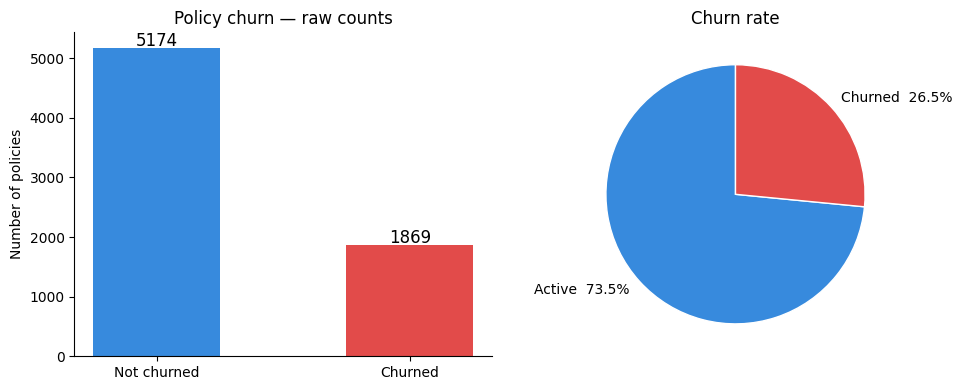

Chart saved as chart_01_class_balance.png


In [8]:
churn_counts = df['churned'].value_counts()
churn_pct    = df['churned'].value_counts(normalize=True) * 100

print('=== CLASS BALANCE ===')
print(f'Not churned : {churn_counts[0]:,} ({churn_pct[0]:.1f}%)')
print(f'Churned     : {churn_counts[1]:,} ({churn_pct[1]:.1f}%)')
print(f'\nImbalance ratio: {churn_counts[0]/churn_counts[1]:.1f}:1')

# Chart
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(['Not churned', 'Churned'], churn_counts,
            color=['#378ADD', '#E24B4A'], width=0.5)
axes[0].set_title('Policy churn — raw counts')
axes[0].set_ylabel('Number of policies')
for i, v in enumerate(churn_counts):
    axes[0].text(i, v + 30, str(v), ha='center', fontsize=12)

axes[1].pie([churn_pct[0], churn_pct[1]],
            labels=[f'Active  {churn_pct[0]:.1f}%', f'Churned  {churn_pct[1]:.1f}%'],
            colors=['#378ADD', '#E24B4A'], startangle=90,
            wedgeprops={'linewidth': 1, 'edgecolor': 'white'})
axes[1].set_title('Churn rate')

plt.tight_layout()
plt.savefig('chart_01_class_balance.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart saved as chart_01_class_balance.png')

## Cell 6 — Churn by contract type

Contract type is typically the strongest predictor — month-to-month policies churn far more.

=== CHURN RATE BY CONTRACT TYPE ===
  Month-to-month      : 42.7%
  One year            : 11.3%
  Two year            : 2.8%


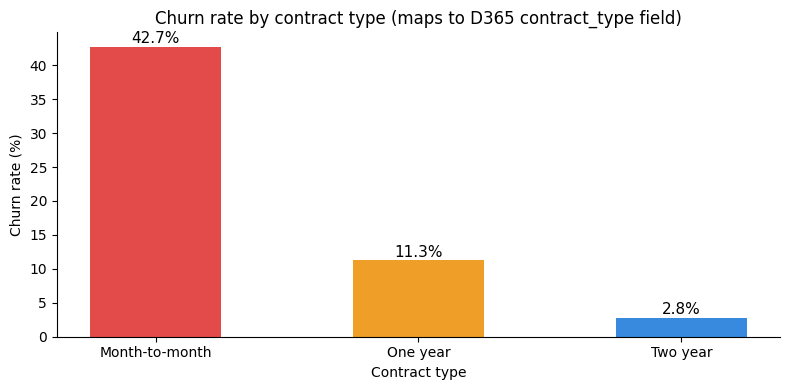

In [9]:
contract_churn = df.groupby('contract_type')['churned'].mean() * 100
contract_churn = contract_churn.sort_values(ascending=False)

print('=== CHURN RATE BY CONTRACT TYPE ===')
for c, v in contract_churn.items():
    print(f'  {c:20s}: {v:.1f}%')

colors = ['#E24B4A' if v > 30 else '#EF9F27' if v > 10 else '#378ADD'
          for v in contract_churn.values]

plt.figure(figsize=(8, 4))
bars = plt.bar(contract_churn.index, contract_churn.values, color=colors, width=0.5)
plt.title('Churn rate by contract type (maps to D365 contract_type field)')
plt.ylabel('Churn rate (%)')
plt.xlabel('Contract type')
for bar, val in zip(bars, contract_churn.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{val:.1f}%', ha='center', fontsize=11)
plt.tight_layout()
plt.savefig('chart_02_churn_by_contract.png', dpi=150, bbox_inches='tight')
plt.show()

## Cell 7 — Churn vs policy tenure

New policyholders churn most. Long-tenure customers are loyal. This is a classic CRM insight.

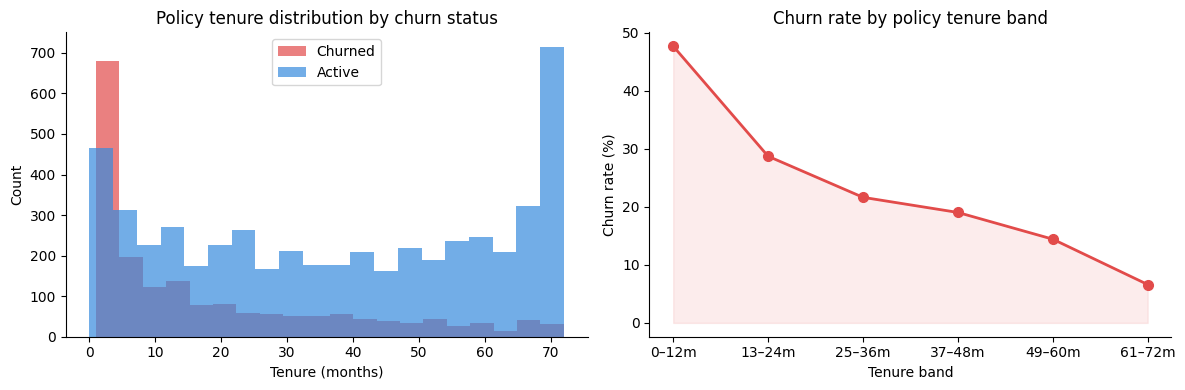

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Distribution of tenure for churned vs active
churned_tenure    = df[df['churned'] == 1]['policy_tenure_months']
not_churned_tenure = df[df['churned'] == 0]['policy_tenure_months']

axes[0].hist(churned_tenure,    bins=20, alpha=0.7, color='#E24B4A', label='Churned')
axes[0].hist(not_churned_tenure, bins=20, alpha=0.7, color='#378ADD', label='Active')
axes[0].set_title('Policy tenure distribution by churn status')
axes[0].set_xlabel('Tenure (months)')
axes[0].set_ylabel('Count')
axes[0].legend()

# Average churn rate per 12-month bucket
df['tenure_band'] = pd.cut(df['policy_tenure_months'],
                            bins=[0, 12, 24, 36, 48, 60, 72],
                            labels=['0–12m', '13–24m', '25–36m', '37–48m', '49–60m', '61–72m'])
tenure_churn = df.groupby('tenure_band', observed=True)['churned'].mean() * 100

axes[1].plot(tenure_churn.index, tenure_churn.values,
             marker='o', color='#E24B4A', linewidth=2, markersize=7)
axes[1].fill_between(range(len(tenure_churn)), tenure_churn.values,
                     alpha=0.1, color='#E24B4A')
axes[1].set_title('Churn rate by policy tenure band')
axes[1].set_xlabel('Tenure band')
axes[1].set_ylabel('Churn rate (%)')

plt.tight_layout()
plt.savefig('chart_03_tenure_vs_churn.png', dpi=150, bbox_inches='tight')
plt.show()

## Cell 8 — Monthly premium vs churn

Higher premiums often correlate with higher churn — affordability is a real driver.

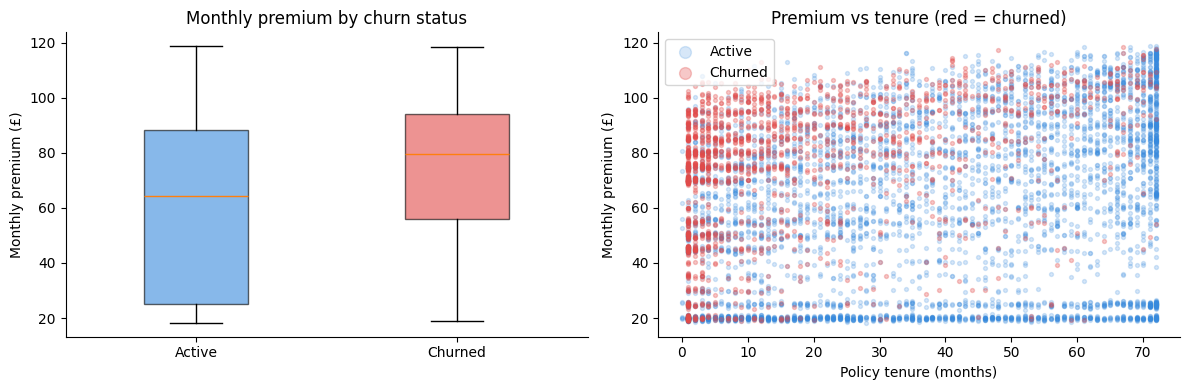

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Box plot — premium by churn status
churned_labels = df['churned'].map({1: 'Churned', 0: 'Active'})
df_plot = df.copy()
df_plot['Status'] = churned_labels

for i, (label, group) in enumerate(df_plot.groupby('Status')):
    axes[0].boxplot(group['monthly_premium'],
                    positions=[i], widths=0.4,
                    patch_artist=True,
                    boxprops=dict(facecolor='#E24B4A' if label=='Churned' else '#378ADD',
                                  alpha=0.6))
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Active', 'Churned'])
axes[0].set_title('Monthly premium by churn status')
axes[0].set_ylabel('Monthly premium (£)')

# Scatter — premium vs tenure, coloured by churn
active  = df[df['churned'] == 0]
churned = df[df['churned'] == 1]
axes[1].scatter(active['policy_tenure_months'],  active['monthly_premium'],
                alpha=0.2, s=8, color='#378ADD', label='Active')
axes[1].scatter(churned['policy_tenure_months'], churned['monthly_premium'],
                alpha=0.3, s=8, color='#E24B4A', label='Churned')
axes[1].set_title('Premium vs tenure (red = churned)')
axes[1].set_xlabel('Policy tenure (months)')
axes[1].set_ylabel('Monthly premium (£)')
axes[1].legend(markerscale=3)

plt.tight_layout()
plt.savefig('chart_04_premium_vs_churn.png', dpi=150, bbox_inches='tight')
plt.show()

## Cell 9 — Correlation heatmap

See at a glance which numeric features are most correlated with churn.

In [ ]:
numeric_cols = ['is_senior', 'policy_tenure_months', 'monthly_premium',
                'total_premiums_paid', 'churned']

corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(7, 5))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(corr_matrix,
            annot=True, fmt='.2f',
            cmap='RdBu_r', center=0,
            square=True, linewidths=0.5,
            cbar_kws={'shrink': 0.8})
plt.title('Correlation matrix — numeric features vs churn')
plt.tight_layout()
plt.savefig('chart_05_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nCorrelations with churn (sorted):')
print(corr_matrix['churned'].drop('churned').sort_values(ascending=False))

## Cell 10 — Phase 1 summary

Summarise what you found — this becomes the 'Data Analysis' section of your dissertation.

In [ ]:
print('=' * 55)
print('PHASE 1 SUMMARY — KEY FINDINGS')
print('=' * 55)

total          = len(df)
churn_rate     = df['churned'].mean() * 100
month_to_month = df[df['contract_type'] == 'Month-to-month']['churned'].mean() * 100
avg_tenure_c   = df[df['churned'] == 1]['policy_tenure_months'].mean()
avg_tenure_a   = df[df['churned'] == 0]['policy_tenure_months'].mean()
avg_prem_c     = df[df['churned'] == 1]['monthly_premium'].mean()
avg_prem_a     = df[df['churned'] == 0]['monthly_premium'].mean()

print(f'Total policies analysed   : {total:,}')
print(f'Overall churn rate        : {churn_rate:.1f}%')
print(f'Month-to-month churn rate : {month_to_month:.1f}%  <-- highest risk segment')
print(f'Avg tenure (churned)      : {avg_tenure_c:.0f} months')
print(f'Avg tenure (active)       : {avg_tenure_a:.0f} months')
print(f'Avg premium (churned)     : £{avg_prem_c:.2f}/month')
print(f'Avg premium (active)      : £{avg_prem_a:.2f}/month')
print()
print('Top risk factors identified:')
print('  1. Month-to-month contract type')
print('  2. Short policy tenure (< 12 months)')
print('  3. Higher monthly premium')
print('  4. No additional cover add-ons')
print()
print('Next step: Phase 2 — Build Logistic Regression + XGBoost models')
print('=' * 55)